# Back-to-school survey: our store vs the competition

**Data source:** `BackToSchool.xlsx` (sheet `back-to-school-data`), back-to-school shopping survey, % of favourable answers.
**Updated:** November 2026
**Author:** Guillem
**Description:** 10 static charts for the board of directors comparing how customers rate **our store** against **all stores** on 12 attributes.
Charts follow the course guides: `draco-vis-guidelines`, `data-viz-best-practices`, `wcag-accessibility`, `pattern-rules`.

---

## Contents
1. Data loading
2. Initial exploration
3. Cleaning and preparation
4. Analysis
5. Accessible visualisation (10 charts)
6. Export
7. Conclusions

In [1]:
# ── Imports and global configuration ─────────────────────────────────────────
import pandas as pd
import altair as alt
from pathlib import Path

alt.data_transformers.disable_max_rows()
alt.renderers.enable('svg')            # WCAG: SVG, never canvas

DATA_FILE  = Path('BackToSchool.xlsx')
OUTPUT_DIR = Path('charts')
OUTPUT_DIR.mkdir(exist_ok=True)

# Palette (Paul Tol / Wong family, colour-blind safe). Contrast on white checked:
OUR_COLOR    = '#4477AA'   # our store / ahead   4.7:1
COMP_FILL    = '#D9D9D9'   # competitors fill (always paired with a dark outline)
COMP_STROKE  = '#767676'   # competitors outline 4.5:1
BEHIND_COLOR = '#B35900'   # behind (dark orange) 4.8:1  — blue/orange, never red/green
PAR_COLOR    = '#8C8C8C'   # on par               3.4:1 (graphic objects ≥ 3:1)
TEXT_DARK, TEXT_MID, GRID = '#1A1A1A', '#595959', '#DDDDDD'
FONT = 'Arial, Liberation Sans, Helvetica, sans-serif'   # fallback list so PNG export never drops text

STATUS_ORDER  = ['Ahead', 'On par', 'Behind']
STATUS_COLORS = [OUR_COLOR, PAR_COLOR, BEHIND_COLOR]
STATUS_TEXT   = [OUR_COLOR, TEXT_MID, BEHIND_COLOR]  # text needs ≥ 4.5:1, so on-par text uses dark grey
STATUS_SHAPES = ['circle', 'square', 'triangle-down']   # redundant to colour
STATUS_DASH   = [[1, 0], [2, 2], [6, 3]]                # redundant to colour (lines)

def style(chart, width=720, height=380):
    """Shared figure/ground styling: soft grid, mid-grey labels, no frame."""
    return (chart.properties(width=width, height=height)
        .configure(font=FONT)
        .configure_title(fontSize=20, fontWeight=600, color=TEXT_DARK, anchor='start',
                         subtitleFontSize=13, subtitleColor=TEXT_MID, offset=14)
        .configure_axis(labelColor=TEXT_MID, titleColor='#333333', labelFontSize=13,
                        titleFontSize=13, gridColor=GRID, gridOpacity=0.6,
                        domainColor='#BBBBBB', tickColor='#BBBBBB', labelLimit=260)
        .configure_legend(labelColor=TEXT_MID, titleColor='#333333', labelFontSize=13,
                          titleFontSize=13, orient='top', labelLimit=260)
        .configure_view(strokeWidth=0))

## 1. Data loading

In [2]:
# ── Load ──────────────────────────────────────────────────────────────────────
# The table sits at B3:F18 with a title row and a two-level header: read the
# raw block and pick the attribute and the two '% favourable' columns.
raw = pd.read_excel(DATA_FILE, sheet_name=0, header=None)
raw = raw.dropna(how='all').dropna(axis=1, how='all')
raw

,1,3,4,5
2,Back-to-school shopping survey results,NaN,NaN,NaN
4,NaN,NaN,% FAVORABLE,NaN
5,STORE OFFERS…,NaN,Our store,All stores
6,NaN,The store is well-organized.,0.4,0.38
7,NaN,Fast and easy checkout.,0.33,0.34
8,NaN,Friendly and helpful employees.,0.45,0.5
9,NaN,Good promotions.,0.45,0.65
10,NaN,I can find what I'm looking for.,0.46,0.55
11,NaN,I can find the size I need.,0.39,0.49
12,NaN,A nice atmosphere.,0.8,0.7


### Decision: manual header parsing
**Context:** the sheet is formatted for people (title, merged headers), not as a tidy table.
**Decision taken:** keep only rows whose attribute text is filled and whose two values are numeric; columns are renamed `our` and `all_stores`.

In [3]:
survey = raw.iloc[:, [-3, -2, -1]].copy()
survey.columns = ['attribute', 'our', 'all_stores']
survey = survey[pd.to_numeric(survey['our'], errors='coerce').notna()].reset_index(drop=True)
survey[['our', 'all_stores']] = survey[['our', 'all_stores']].astype(float)
print(f'Rows: {survey.shape[0]} | Columns: {survey.shape[1]}')
survey

Rows: 12 | Columns: 3


,attribute,our,all_stores
0,The store is well-organized.,0.40,0.38
1,Fast and easy checkout.,0.33,0.34
2,Friendly and helpful employees.,0.45,0.50
3,Good promotions.,0.45,0.65
4,I can find what I'm looking for.,0.46,0.55
5,I can find the size I need.,0.39,0.49
6,A nice atmosphere.,0.80,0.70
7,Latest technology for easy shopping.,0.35,0.34
8,Lowest sales prices.,0.40,0.60
9,A wide selection.,0.49,0.47


## 2. Initial exploration

In [4]:
print('Null values:', int(survey.isnull().sum().sum()))
survey[['our', 'all_stores']].describe().round(3)

Null values: 0


,our,all_stores
count,12.000,12.000
mean,0.493,0.509
std,0.154,0.115
min,0.330,0.340
25%,0.398,0.448
50%,0.450,0.520
75%,0.530,0.562
max,0.800,0.700


**Key findings:** 12 attributes, no nulls, values between 33% and 80%. "All stores" is the market benchmark (it is the comparison the survey offers for the competition).

> ⚠️ **Limitation:** the file gives no sample sizes, so differences of 1–2 points cannot be told apart from noise. Below, |gap| ≤ 2 pp is labelled *On par*.

## 3. Cleaning and preparation

In [5]:
# Short labels for slides (full wording kept for tooltips)
SHORT = {
    'The store is well-organized.': 'Well-organized store',
    'Fast and easy checkout.': 'Fast checkout',
    'Friendly and helpful employees.': 'Helpful employees',
    'Good promotions.': 'Good promotions',
    "I can find what I'm looking for.": 'Find what I need',
    'I can find the size I need.': 'Find my size',
    'A nice atmosphere.': 'Nice atmosphere',
    'Latest technology for easy shopping.': 'Shopping technology',
    'Lowest sales prices.': 'Lowest prices',
    'A wide selection.': 'Wide selection',
    "Items I can't find elsewhere.": 'Unique items',
    'The latest styles.': 'Latest styles',
}
# Themes (our own grouping, for the board discussion)
THEME = {
    'Good promotions': 'Price & promotions', 'Lowest prices': 'Price & promotions',
    'Helpful employees': 'Service', 'Fast checkout': 'Service', 'Find what I need': 'Service',
    'Wide selection': 'Assortment', 'Unique items': 'Assortment',
    'Latest styles': 'Assortment', 'Find my size': 'Assortment',
    'Well-organized store': 'Store experience', 'Nice atmosphere': 'Store experience',
    'Shopping technology': 'Store experience',
}
PARITY_PP = 2

clean = survey.copy()
clean['attribute_full'] = clean['attribute'].str.strip()
clean['label'] = clean['attribute_full'].map(SHORT)
clean['theme'] = clean['label'].map(THEME)
clean['gap_pp'] = ((clean['our'] - clean['all_stores']) * 100).round(0)
clean['status'] = pd.cut(clean['gap_pp'], [-100, -PARITY_PP - 0.5, PARITY_PP + 0.5, 100],
                         labels=['Behind', 'On par', 'Ahead']).astype(str)
clean['gap_text'] = clean['gap_pp'].map(lambda v: f'{v:+.0f} pp')
assert clean['label'].notna().all() and clean['theme'].notna().all()

# Long format: one row per attribute × store
long = clean.melt(id_vars=['label', 'attribute_full', 'gap_pp', 'gap_text', 'status', 'theme'],
                  value_vars=['our', 'all_stores'], var_name='store', value_name='favorable')
long['store'] = long['store'].map({'our': 'Our store', 'all_stores': 'All stores'})
ORDER_BY_GAP = clean.sort_values('gap_pp', ascending=False)['label'].tolist()
clean.sort_values('gap_pp', ascending=False)

,attribute,our,all_stores,attribute_full,label,theme,gap_pp,status,gap_text
10,Items I can't find elsewhere.,0.74,0.54,Items I can't find elsewhere.,Unique items,Assortment,20.0,Ahead,+20 pp
6,A nice atmosphere.,0.80,0.70,A nice atmosphere.,Nice atmosphere,Store experience,10.0,Ahead,+10 pp
11,The latest styles.,0.65,0.55,The latest styles.,Latest styles,Assortment,10.0,Ahead,+10 pp
0,The store is well-organized.,0.40,0.38,The store is well-organized.,Well-organized store,Store experience,2.0,On par,+2 pp
9,A wide selection.,0.49,0.47,A wide selection.,Wide selection,Assortment,2.0,On par,+2 pp
7,Latest technology for easy shopping.,0.35,0.34,Latest technology for easy shopping.,Shopping technology,Store experience,1.0,On par,+1 pp
1,Fast and easy checkout.,0.33,0.34,Fast and easy checkout.,Fast checkout,Service,-1.0,On par,-1 pp
2,Friendly and helpful employees.,0.45,0.50,Friendly and helpful employees.,Helpful employees,Service,-5.0,Behind,-5 pp
4,I can find what I'm looking for.,0.46,0.55,I can find what I'm looking for.,Find what I need,Service,-9.0,Behind,-9 pp
5,I can find the size I need.,0.39,0.49,I can find the size I need.,Find my size,Assortment,-10.0,Behind,-10 pp


### Decision: gap in percentage points and a ±2 pp parity band
**Decision taken:** the comparison metric is `Our − All stores` in percentage points (pp). Bars encode it from 0 (Draco `bar_area_without_zero`). Without sample sizes, ±2 pp is treated as parity.

## 4. Analysis

In [6]:
overall = pd.DataFrame({
    'store': ['Our store', 'All stores'],
    'favorable': [clean['our'].mean(), clean['all_stores'].mean()],
})
status_count = (clean['status'].value_counts().reindex(STATUS_ORDER).rename_axis('status')
                .reset_index(name='n'))
theme_gap = (clean.groupby('theme').agg(gap_pp=('gap_pp', 'mean'), n=('gap_pp', 'size'))
             .reset_index().sort_values('gap_pp', ascending=False))
theme_gap['status'] = pd.cut(theme_gap['gap_pp'], [-100, -PARITY_PP - 0.5, PARITY_PP + 0.5, 100],
                             labels=['Behind', 'On par', 'Ahead']).astype(str)
theme_gap['gap_text'] = theme_gap['gap_pp'].map(lambda v: f'{v:+.1f} pp')
display(overall.round(3), status_count, theme_gap.round(1))

,store,favorable
0,Our store,0.493
1,All stores,0.509


,status,n
0,Ahead,3
1,On par,4
2,Behind,5


,theme,gap_pp,n,status,gap_text
0,Assortment,5.5,4,Ahead,+5.5 pp
3,Store experience,4.3,3,Ahead,+4.3 pp
2,Service,-5.0,3,Behind,-5.0 pp
1,Price & promotions,-20.0,2,Behind,-20.0 pp


**Interpretation:** on average we are ~2 pp below the market. We lead clearly on *unique items*, *latest styles* and *atmosphere*; we trail on *price/promotions* (−20 pp) and on everything that depends on staff (*helpful employees*, *find what I need*, *find my size*).

## 5. Accessible visualisation

Rules applied to every chart:
- **Draco:** quantity always on position (x/y); bars start at 0; nominal fields on y; ≤ 3 colours; no stacking of means.
- **Colour:** blue = us / ahead, orange = behind, grey = competition / on par (colour-blind safe, never red + green). Contrast ≥ 3:1 for marks, ≥ 4.5:1 for text.
- **Never colour alone (WCAG 1.4.1):** direct value labels, plus a second channel (solid vs outlined bars, shape, dash) wherever colour separates categories.
- **One chart = one question**, descriptive action titles, SVG rendering.

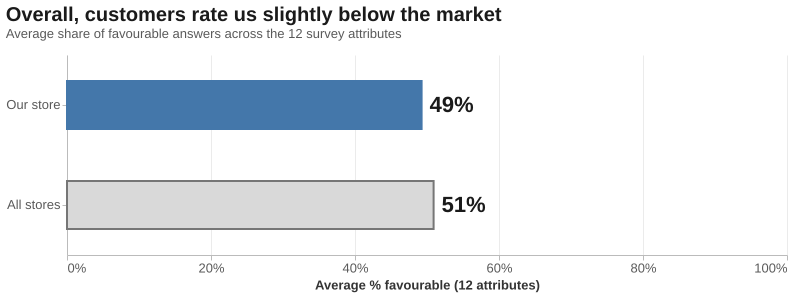

In [7]:
# ── Chart 1 · Overall average ─────────────────────────────────────────────────
base = alt.Chart(overall).encode(
    y=alt.Y('store:N', sort=['Our store', 'All stores'], title=None),
    x=alt.X('favorable:Q', title='Average % favourable (12 attributes)',
            axis=alt.Axis(format='%', tickCount=5), scale=alt.Scale(domain=[0, 1])),
    tooltip=[alt.Tooltip('store:N', title='Store'),
             alt.Tooltip('favorable:Q', title='Avg. favourable', format='.1%')])
bars = base.mark_bar(height=48, strokeWidth=2).encode(
    color=alt.Color('store:N', scale=alt.Scale(domain=['Our store', 'All stores'],
                    range=[OUR_COLOR, COMP_FILL]), legend=None),
    stroke=alt.Stroke('store:N', scale=alt.Scale(domain=['Our store', 'All stores'],
                    range=[OUR_COLOR, COMP_STROKE]), legend=None))
labels = base.mark_text(align='left', dx=8, fontSize=22, fontWeight='bold', color=TEXT_DARK
                        ).encode(text=alt.Text('favorable:Q', format='.0%'))
chart1 = style((bars + labels).properties(title=alt.Title(
    'Overall, customers rate us slightly below the market',
    subtitle='Average share of favourable answers across the 12 survey attributes')), height=200)
chart1

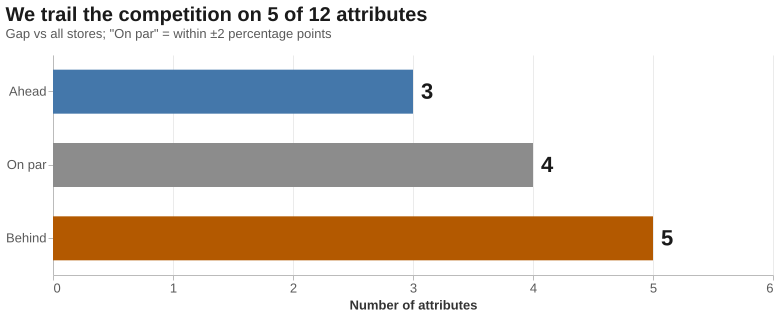

In [8]:
# ── Chart 2 · Scorecard: attributes ahead / on par / behind ──────────────────
base = alt.Chart(status_count).encode(
    y=alt.Y('status:N', sort=STATUS_ORDER, title=None),
    x=alt.X('n:Q', title='Number of attributes', scale=alt.Scale(domain=[0, 6]),
            axis=alt.Axis(tickMinStep=1, format='d')),
    tooltip=[alt.Tooltip('status:N', title='Status'), alt.Tooltip('n:Q', title='Attributes')])
bars = base.mark_bar(height=44).encode(color=alt.Color('status:N', legend=None,
        scale=alt.Scale(domain=STATUS_ORDER, range=STATUS_COLORS)))
labels = base.mark_text(align='left', dx=8, fontSize=22, fontWeight='bold', color=TEXT_DARK
                        ).encode(text='n:Q')
chart2 = style((bars + labels).properties(title=alt.Title(
    'We trail the competition on 5 of 12 attributes',
    subtitle=f'Gap vs all stores; "On par" = within ±{PARITY_PP} percentage points')), height=220)
chart2

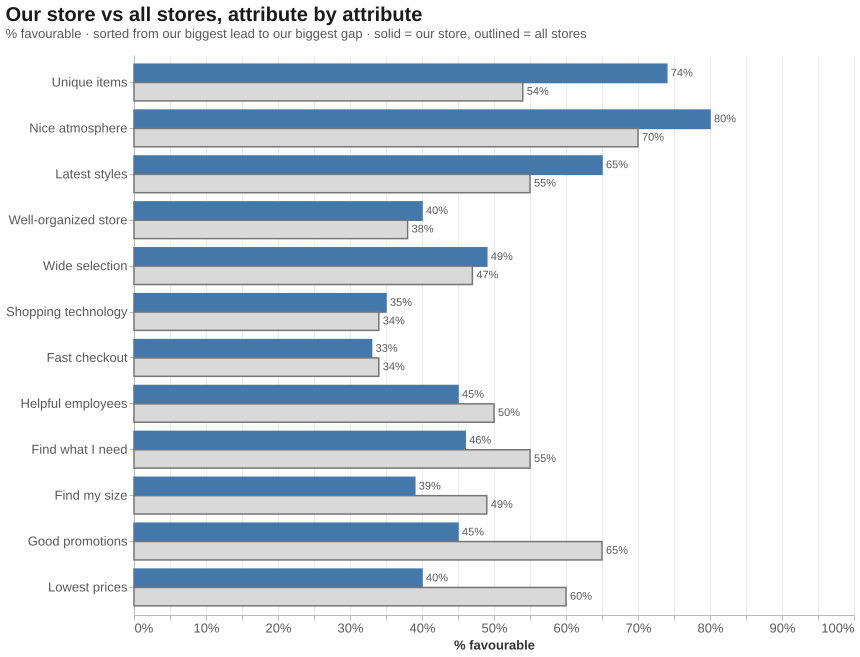

In [9]:
# ── Chart 3 · Grouped bars, every attribute ──────────────────────────────────
STORE_DOM = ['Our store', 'All stores']
base = alt.Chart(long).encode(
    y=alt.Y('label:N', sort=ORDER_BY_GAP, title=None),
    yOffset=alt.YOffset('store:N', sort=STORE_DOM),
    x=alt.X('favorable:Q', title='% favourable', axis=alt.Axis(format='%'),
            scale=alt.Scale(domain=[0, 1])),
    tooltip=[alt.Tooltip('attribute_full:N', title='Attribute'), alt.Tooltip('store:N', title='Store'),
             alt.Tooltip('favorable:Q', title='% favourable', format='.0%')])
bars = base.mark_bar(strokeWidth=1.5).encode(
    color=alt.Color('store:N', title=None, sort=STORE_DOM,
                    scale=alt.Scale(domain=STORE_DOM, range=[OUR_COLOR, COMP_FILL])),
    stroke=alt.Stroke('store:N', sort=STORE_DOM, legend=None,
                      scale=alt.Scale(domain=STORE_DOM, range=[OUR_COLOR, COMP_STROKE])))
labels = base.mark_text(align='left', dx=4, fontSize=11, color=TEXT_MID).encode(
    text=alt.Text('favorable:Q', format='.0%'))
chart3 = style((bars + labels).properties(title=alt.Title(
    'Our store vs all stores, attribute by attribute',
    subtitle='% favourable · sorted from our biggest lead to our biggest gap · solid = our store, outlined = all stores')),
    height=560)
chart3

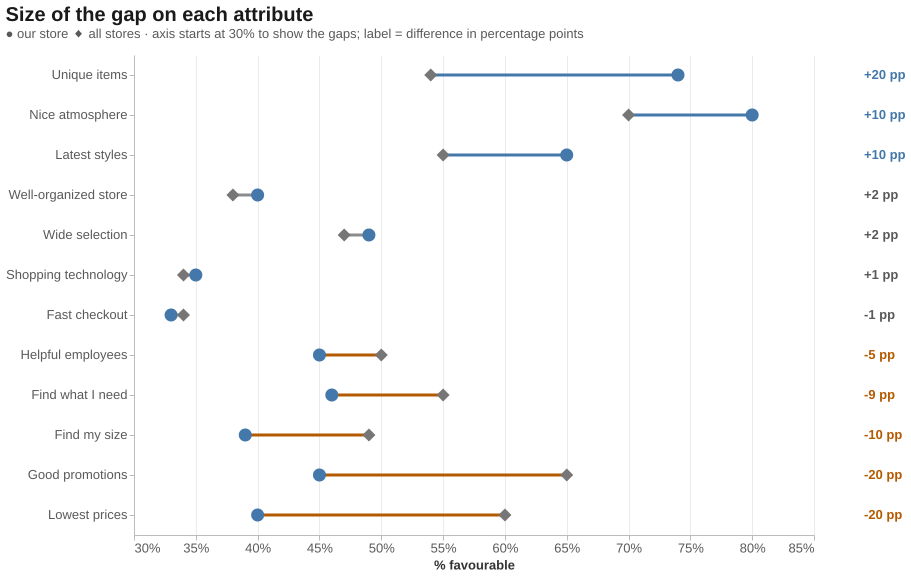

In [10]:
# ── Chart 4 · Dumbbell (dot plot) ────────────────────────────────────────────
y_enc = alt.Y('label:N', sort=ORDER_BY_GAP, title=None)
rule = alt.Chart(clean).mark_rule(strokeWidth=3).encode(
    y=y_enc, x=alt.X('all_stores:Q', title='% favourable', axis=alt.Axis(format='%'),
                     scale=alt.Scale(domain=[0.3, 0.85])),
    x2='our:Q',
    color=alt.Color('status:N', legend=None, scale=alt.Scale(domain=STATUS_ORDER, range=STATUS_COLORS)))
dots = alt.Chart(long).mark_point(filled=True, size=170, opacity=1).encode(
    y=y_enc, x='favorable:Q',
    color=alt.Color('store:N', legend=None, sort=STORE_DOM,
                    scale=alt.Scale(domain=STORE_DOM, range=[OUR_COLOR, COMP_STROKE])),
    shape=alt.Shape('store:N', legend=None, sort=STORE_DOM,
                    scale=alt.Scale(domain=STORE_DOM, range=['circle', 'diamond'])),
    tooltip=[alt.Tooltip('attribute_full:N', title='Attribute'), alt.Tooltip('store:N', title='Store'),
             alt.Tooltip('favorable:Q', title='% favourable', format='.0%')])
gap_lbl = alt.Chart(clean).mark_text(align='left', x=730, fontSize=13, fontWeight='bold').encode(
    y=y_enc, text='gap_text:N',
    color=alt.Color('status:N', legend=None, scale=alt.Scale(domain=STATUS_ORDER, range=STATUS_TEXT)))
chart4 = style((rule + dots + gap_lbl).resolve_scale(color='independent').properties(title=alt.Title(
    'Size of the gap on each attribute',
    subtitle='● our store  ◆ all stores · axis starts at 30% to show the gaps; label = difference in percentage points')),
    width=680, height=480)
chart4

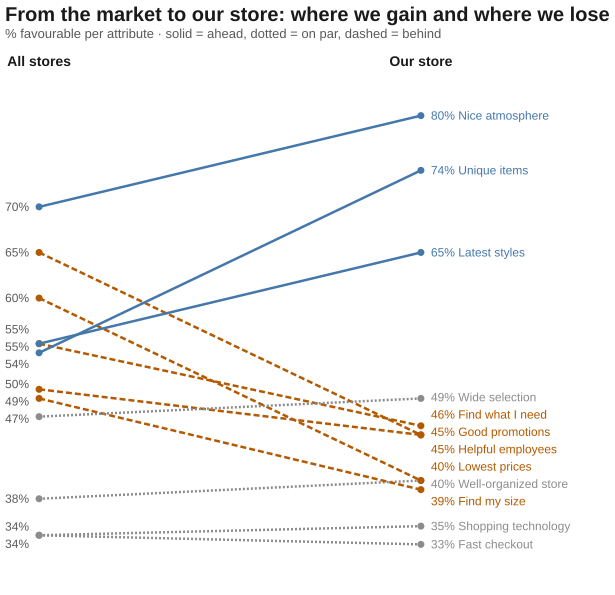

In [11]:
# ── Chart 5 · Slopegraph ──────────────────────────────────────────────────────
# Labels are nudged apart (simple 1-D repel) so close values stay readable.
def repel(values, min_gap, iters=500):
    # push overlapping labels apart symmetrically so each stays close to its point
    y = list(values)
    for _ in range(iters):
        order = sorted(range(len(y)), key=lambda i: y[i])
        moved = False
        for a, b in zip(order, order[1:]):
            d = y[b] - y[a]
            if d < min_gap:
                shift = (min_gap - d) / 2
                y[a] -= shift; y[b] += shift; moved = True
        if not moved:
            break
    return y

slope = long.copy()
slope['x'] = slope['store'].map({'All stores': 0, 'Our store': 1})
slope['label_y'] = 0.0
for st in STORE_DOM:
    m = slope['store'] == st
    slope.loc[m, 'label_y'] = repel(slope.loc[m, 'favorable'].tolist(), 0.019)
slope['txt_left'] = slope['favorable'].map('{:.0%}'.format)
slope['txt_right'] = slope.apply(lambda r: f"{r.favorable:.0%}  {r.label}", axis=1)

y_scale = alt.Scale(domain=[0.28, 0.85])
color_status = alt.Color('status:N', title=None, sort=STATUS_ORDER,
                         scale=alt.Scale(domain=STATUS_ORDER, range=STATUS_COLORS))
dash_status = alt.StrokeDash('status:N', title=None, sort=STATUS_ORDER,
                             scale=alt.Scale(domain=STATUS_ORDER, range=STATUS_DASH))
x_enc = alt.X('x:Q', scale=alt.Scale(domain=[-0.05, 1.05]), axis=None)
lines = alt.Chart(slope).mark_line(strokeWidth=2.5, point=alt.OverlayMarkDef(size=50, filled=True)).encode(
    x=x_enc, y=alt.Y('favorable:Q', scale=y_scale, axis=None), detail='label:N',
    color=color_status, strokeDash=dash_status,
    tooltip=[alt.Tooltip('attribute_full:N', title='Attribute'), alt.Tooltip('store:N', title='Store'),
             alt.Tooltip('favorable:Q', title='% favourable', format='.0%'),
             alt.Tooltip('gap_text:N', title='Gap')])
txt_r = alt.Chart(slope[slope.x == 1]).mark_text(align='left', dx=10, fontSize=12).encode(
    x=x_enc, y=alt.Y('label_y:Q', scale=y_scale, axis=None), text='txt_right:N',
    color=alt.Color('status:N', legend=None, scale=alt.Scale(domain=STATUS_ORDER, range=STATUS_TEXT)))
txt_l = alt.Chart(slope[slope.x == 0]).mark_text(align='right', dx=-10, fontSize=12, color=TEXT_MID).encode(
    x=x_enc, y=alt.Y('label_y:Q', scale=y_scale, axis=None), text='txt_left:N')
heads = alt.Chart(pd.DataFrame({'x': [0, 1], 't': ['All stores', 'Our store']})).mark_text(
    fontSize=14, fontWeight='bold', color=TEXT_DARK, dy=-8).encode(x=x_enc, y=alt.value(0), text='t:N')
chart5 = style((lines + txt_r + txt_l + heads).properties(title=alt.Title(
    'From the market to our store: where we gain and where we lose',
    subtitle='% favourable per attribute · solid = ahead, dotted = on par, dashed = behind')),
    width=420, height=520).configure_legend(orient='bottom', labelFontSize=13, labelColor=TEXT_MID)
chart5

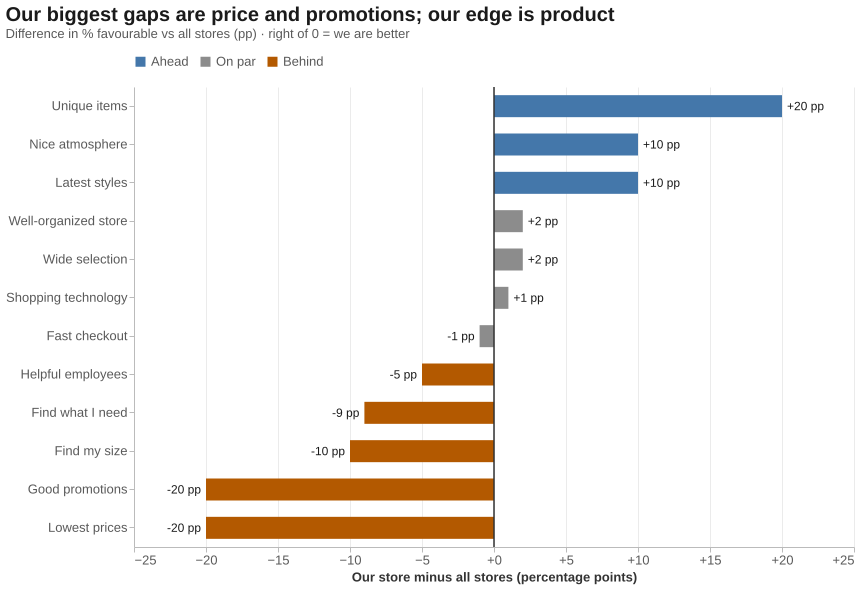

In [12]:
# ── Chart 6 · Diverging gap bars ─────────────────────────────────────────────
base = alt.Chart(clean).encode(
    y=alt.Y('label:N', sort=ORDER_BY_GAP, title=None),
    x=alt.X('gap_pp:Q', title='Our store minus all stores (percentage points)',
            scale=alt.Scale(domain=[-25, 25]), axis=alt.Axis(format='+d', values=list(range(-25, 26, 5)))),
    tooltip=[alt.Tooltip('attribute_full:N', title='Attribute'), alt.Tooltip('gap_text:N', title='Gap'),
             alt.Tooltip('our:Q', title='Our store', format='.0%'),
             alt.Tooltip('all_stores:Q', title='All stores', format='.0%')])
bars = base.mark_bar(height=22).encode(color=alt.Color('status:N', title=None, sort=STATUS_ORDER,
        scale=alt.Scale(domain=STATUS_ORDER, range=STATUS_COLORS)))
lbl_pos = base.transform_filter('datum.gap_pp >= 0').mark_text(align='left', dx=5, fontSize=12,
          color=TEXT_DARK).encode(text='gap_text:N')
lbl_neg = base.transform_filter('datum.gap_pp < 0').mark_text(align='right', dx=-5, fontSize=12,
          color=TEXT_DARK).encode(text='gap_text:N')
zero = alt.Chart(pd.DataFrame({'x': [0]})).mark_rule(color='#333333', strokeWidth=1.5).encode(x='x:Q')
chart6 = style((bars + zero + lbl_pos + lbl_neg).properties(title=alt.Title(
    'Our biggest gaps are price and promotions; our edge is product',
    subtitle='Difference in % favourable vs all stores (pp) · right of 0 = we are better')), height=460)
chart6

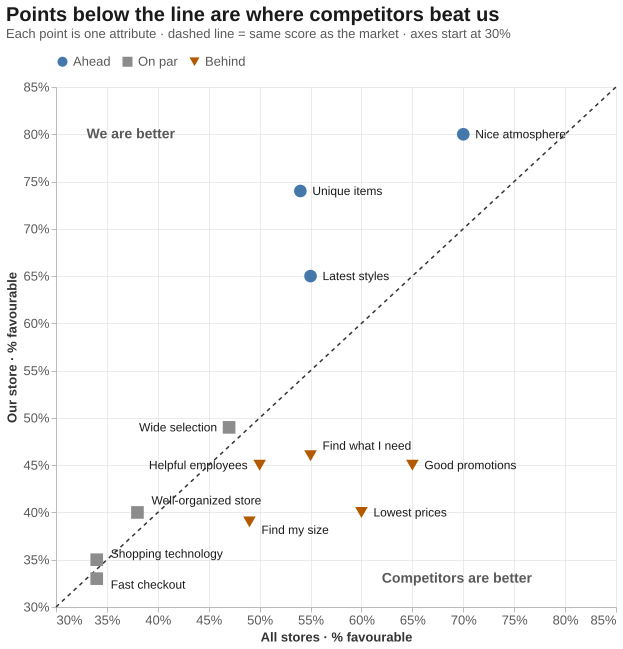

In [13]:
# ── Chart 7 · Scatter: our score vs market score ─────────────────────────────
dom = [0.3, 0.85]
diag = pd.DataFrame({'a': dom, 'b': dom})
parity = alt.Chart(diag).mark_line(color='#333333', strokeDash=[4, 4], strokeWidth=1.5).encode(
    x=alt.X('a:Q', scale=alt.Scale(domain=dom)), y=alt.Y('b:Q', scale=alt.Scale(domain=dom)))
pts = alt.Chart(clean).mark_point(filled=True, size=160, opacity=1).encode(
    x=alt.X('all_stores:Q', title='All stores · % favourable', scale=alt.Scale(domain=dom),
            axis=alt.Axis(format='%')),
    y=alt.Y('our:Q', title='Our store · % favourable', scale=alt.Scale(domain=dom),
            axis=alt.Axis(format='%')),
    color=color_status,
    shape=alt.Shape('status:N', title=None, sort=STATUS_ORDER,
                    scale=alt.Scale(domain=STATUS_ORDER, range=STATUS_SHAPES)),
    tooltip=[alt.Tooltip('attribute_full:N', title='Attribute'),
             alt.Tooltip('our:Q', title='Our store', format='.0%'),
             alt.Tooltip('all_stores:Q', title='All stores', format='.0%'),
             alt.Tooltip('gap_text:N', title='Gap')])
# label placement tuned to avoid overlaps between close points
# label placement (align, dx, dy) tuned by hand to avoid overlaps between close points
nudge = {'Fast checkout': ('left', 14, 6), 'Shopping technology': ('left', 14, -6),
         'Well-organized store': ('left', 14, -12), 'Wide selection': ('right', -12, 0),
         'Find my size': ('left', 12, 8), 'Helpful employees': ('right', -12, 0),
         'Find what I need': ('left', 12, -10)}
texts = [alt.Chart(clean[clean.label == l]).mark_text(
             align=nudge.get(l, ('left', 12, 0))[0], dx=nudge.get(l, ('left', 12, 0))[1],
             dy=nudge.get(l, ('left', 12, 0))[2], fontSize=12, color=TEXT_DARK
         ).encode(x='all_stores:Q', y='our:Q', text='label:N') for l in clean['label']]
zones = alt.Chart(pd.DataFrame({'a': [0.33, 0.62], 'b': [0.80, 0.33],
                                't': ['We are better', 'Competitors are better']})).mark_text(
    align='left', fontSize=14, fontWeight='bold', color=TEXT_MID).encode(x='a:Q', y='b:Q', text='t:N')
chart7 = style(alt.layer(parity, zones, pts, *texts).properties(title=alt.Title(
    'Points below the line are where competitors beat us',
    subtitle='Each point is one attribute · dashed line = same score as the market · axes start at 30%')),
    width=560, height=520)
chart7

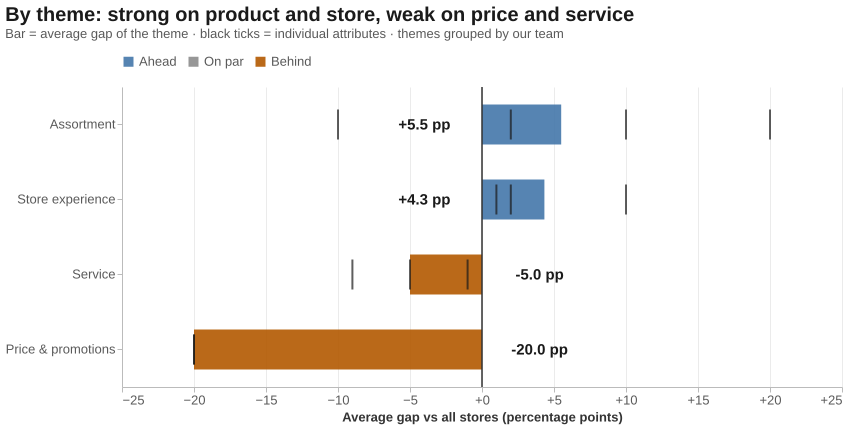

In [14]:
# ── Chart 8 · Gap by theme ───────────────────────────────────────────────────
THEME_ORDER = theme_gap['theme'].tolist()
x_gap = alt.X('gap_pp:Q', title='Average gap vs all stores (percentage points)',
              scale=alt.Scale(domain=[-25, 25]), axis=alt.Axis(format='+d', values=list(range(-25, 26, 5))))
bars = alt.Chart(theme_gap).mark_bar(height=40, opacity=0.9).encode(
    y=alt.Y('theme:N', sort=THEME_ORDER, title=None), x=x_gap,
    color=alt.Color('status:N', title=None, sort=STATUS_ORDER,
                    scale=alt.Scale(domain=STATUS_ORDER, range=STATUS_COLORS)),
    tooltip=[alt.Tooltip('theme:N', title='Theme'), alt.Tooltip('gap_text:N', title='Average gap'),
             alt.Tooltip('n:Q', title='Attributes')])
ticks = alt.Chart(clean).mark_tick(color=TEXT_DARK, thickness=2, size=30).encode(
    y=alt.Y('theme:N', sort=THEME_ORDER, title=None), x=x_gap,
    tooltip=[alt.Tooltip('label:N', title='Attribute'), alt.Tooltip('gap_text:N', title='Gap')])
lbl = alt.Chart(theme_gap).mark_text(fontSize=15, fontWeight='bold', color=TEXT_DARK).encode(
    y=alt.Y('theme:N', sort=THEME_ORDER), text='gap_text:N',
    x=alt.X('pos:Q', scale=alt.Scale(domain=[-25, 25]))).transform_calculate(
    pos='datum.gap_pp >= 0 ? -4 : 4')
zero = alt.Chart(pd.DataFrame({'x': [0]})).mark_rule(color='#333333', strokeWidth=1.5).encode(x='x:Q')
chart8 = style((bars + zero + ticks + lbl).properties(title=alt.Title(
    'By theme: strong on product and store, weak on price and service',
    subtitle='Bar = average gap of the theme · black ticks = individual attributes · themes grouped by our team')),
    height=300)
chart8

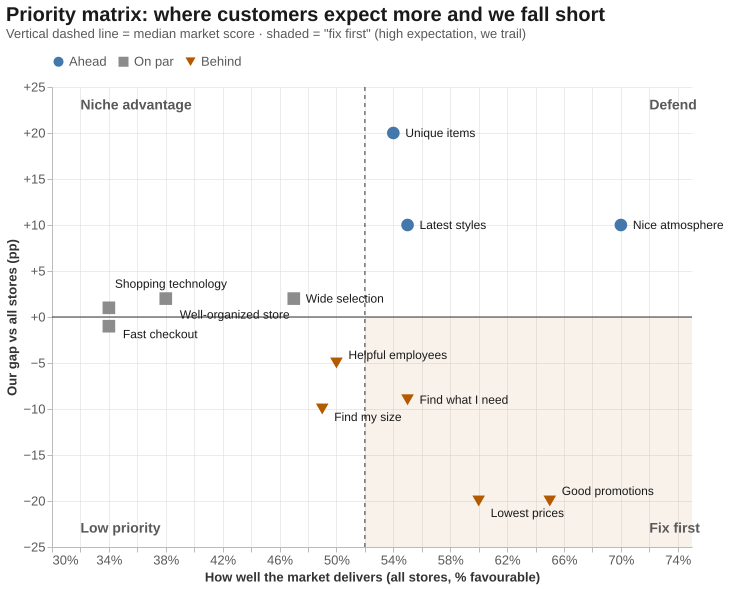

In [15]:
# ── Chart 9 · Priority matrix ────────────────────────────────────────────────
# x: how well the market already delivers (customer expectation)
# y: our gap. High expectation + negative gap = fix first.
mx = clean['all_stores'].median()
quad = pd.DataFrame({'x': [0.32, 0.72, 0.32, 0.72], 'y': [23, 23, -23, -23],
                     't': ['Niche advantage', 'Defend', 'Low priority', 'Fix first']})
x_s = alt.Scale(domain=[0.3, 0.75])
y_s = alt.Scale(domain=[-25, 25])
bg = alt.Chart(pd.DataFrame({'x': [mx], 'x2': [0.75], 'y': [-25], 'y2': [0]})).mark_rect(
    color=BEHIND_COLOR, opacity=0.08).encode(x=alt.X('x:Q', scale=x_s), x2='x2:Q',
                                              y=alt.Y('y:Q', scale=y_s), y2='y2:Q')
h = alt.Chart(pd.DataFrame({'y': [0]})).mark_rule(color='#333333').encode(y='y:Q')
v = alt.Chart(pd.DataFrame({'x': [mx]})).mark_rule(color='#333333', strokeDash=[4, 4]).encode(x='x:Q')
qt = alt.Chart(quad).mark_text(fontSize=14, fontWeight='bold', color=TEXT_MID, align='left').encode(
    x=alt.X('x:Q', scale=x_s), y=alt.Y('y:Q', scale=y_s), text='t:N')
pts = alt.Chart(clean).mark_point(filled=True, size=160, opacity=1).encode(
    x=alt.X('all_stores:Q', scale=x_s, title='How well the market delivers (all stores, % favourable)',
            axis=alt.Axis(format='%')),
    y=alt.Y('gap_pp:Q', scale=y_s, title='Our gap vs all stores (pp)', axis=alt.Axis(format='+d')),
    color=color_status,
    shape=alt.Shape('status:N', title=None, sort=STATUS_ORDER,
                    scale=alt.Scale(domain=STATUS_ORDER, range=STATUS_SHAPES)),
    tooltip=[alt.Tooltip('attribute_full:N', title='Attribute'),
             alt.Tooltip('all_stores:Q', title='All stores', format='.0%'),
             alt.Tooltip('gap_text:N', title='Gap')])
nudge9 = {'Fast checkout': ('left', 14, 8), 'Shopping technology': ('left', 6, -24),
          'Well-organized store': ('left', 14, 16), 'Wide selection': ('left', 12, 0),
          'Find my size': ('left', 12, 8), 'Helpful employees': ('left', 12, -8),
          'Good promotions': ('left', 12, -10), 'Lowest prices': ('left', 12, 12)}
txt = [alt.Chart(clean[clean.label == l]).mark_text(
           align=nudge9.get(l, ('left', 12, 0))[0], dx=nudge9.get(l, ('left', 12, 0))[1],
           dy=nudge9.get(l, ('left', 12, 0))[2], fontSize=12, color=TEXT_DARK
       ).encode(x=alt.X('all_stores:Q', scale=x_s), y=alt.Y('gap_pp:Q', scale=y_s), text='label:N')
       for l in clean['label']]
chart9 = style(alt.layer(bg, h, v, qt, pts, *txt).properties(title=alt.Title(
    'Priority matrix: where customers expect more and we fall short',
    subtitle='Vertical dashed line = median market score · shaded = "fix first" (high expectation, we trail)')),
    width=640, height=460)
chart9

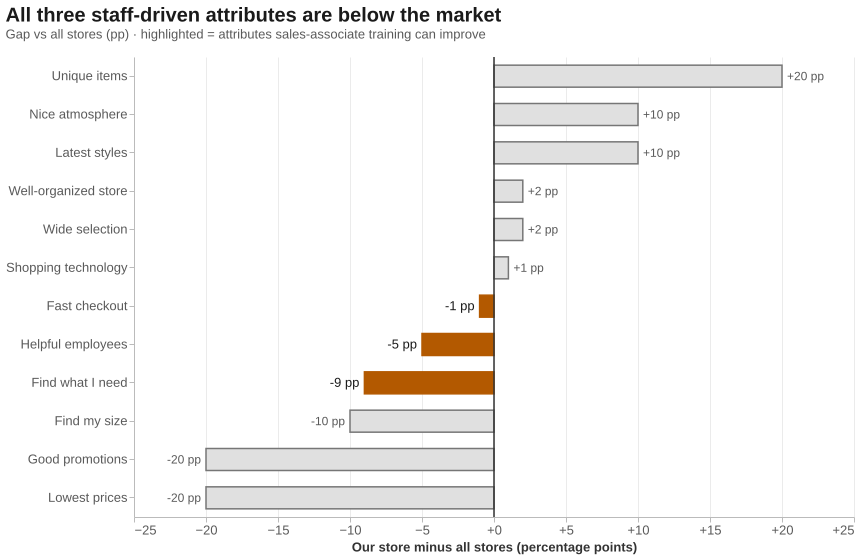

In [16]:
# ── Chart 10 · Service gaps highlighted ──────────────────────────────────────
svc = clean.assign(focus=clean['theme'].eq('Service').map({True: 'Service (staff-driven)', False: 'Other attributes'}))
FOCUS_DOM = ['Service (staff-driven)', 'Other attributes']
base = alt.Chart(svc).encode(
    y=alt.Y('label:N', sort=ORDER_BY_GAP, title=None),
    x=alt.X('gap_pp:Q', title='Our store minus all stores (percentage points)',
            scale=alt.Scale(domain=[-25, 25]), axis=alt.Axis(format='+d', values=list(range(-25, 26, 5)))),
    tooltip=[alt.Tooltip('attribute_full:N', title='Attribute'), alt.Tooltip('theme:N', title='Theme'),
             alt.Tooltip('gap_text:N', title='Gap')])
bars = base.mark_bar(height=22, strokeWidth=1.5).encode(
    color=alt.Color('focus:N', title=None, sort=FOCUS_DOM,
                    scale=alt.Scale(domain=FOCUS_DOM, range=[BEHIND_COLOR, '#E0E0E0'])),
    stroke=alt.Stroke('focus:N', legend=None, scale=alt.Scale(domain=FOCUS_DOM, range=[BEHIND_COLOR, COMP_STROKE])))
def side_labels(cond, align, dx):
    return base.transform_filter(cond).mark_text(fontSize=12, align=align, dx=dx).encode(
        text='gap_text:N',
        color=alt.condition("datum.theme == 'Service'", alt.value(TEXT_DARK), alt.value(TEXT_MID)),
        size=alt.condition("datum.theme == 'Service'", alt.value(13), alt.value(12)))
lbl = side_labels('datum.gap_pp >= 0', 'left', 5) + side_labels('datum.gap_pp < 0', 'right', -5)
zero = alt.Chart(pd.DataFrame({'x': [0]})).mark_rule(color='#333333', strokeWidth=1.5).encode(x='x:Q')
chart10 = style((bars + zero + lbl).properties(title=alt.Title(
    'All three staff-driven attributes are below the market',
    subtitle='Gap vs all stores (pp) · highlighted = attributes sales-associate training can improve')), height=460)
chart10

## 6. Export

In [17]:
# ── Export: SVG (editable/vector) + PNG @2x (slides) + Vega-Lite JSON ─────────
charts = {
    '01_overall_average': chart1, '02_scorecard': chart2, '03_grouped_bars': chart3,
    '04_dumbbell_gap': chart4, '05_slopegraph': chart5, '06_gap_diverging': chart6,
    '07_scatter_vs_market': chart7, '08_gap_by_theme': chart8, '09_priority_matrix': chart9,
    '10_service_gaps': chart10,
}
for name, ch in charts.items():
    ch.save(OUTPUT_DIR / f'{name}.svg')
    ch.save(OUTPUT_DIR / f'{name}.png', scale_factor=2)
    ch.save(OUTPUT_DIR / f'{name}.vl.json')
clean.to_csv(OUTPUT_DIR / 'data_clean.csv', index=False)
sorted(p.name for p in OUTPUT_DIR.iterdir())

['01_overall_average.png',
 '01_overall_average.svg',
 '01_overall_average.vl.json',
 '02_scorecard.png',
 '02_scorecard.svg',
 '02_scorecard.vl.json',
 '03_grouped_bars.png',
 '03_grouped_bars.svg',
 '03_grouped_bars.vl.json',
 '04_dumbbell_gap.png',
 '04_dumbbell_gap.svg',
 '04_dumbbell_gap.vl.json',
 '05_slopegraph.png',
 '05_slopegraph.svg',
 '05_slopegraph.vl.json',
 '06_gap_diverging.png',
 '06_gap_diverging.svg',
 '06_gap_diverging.vl.json',
 '07_scatter_vs_market.png',
 '07_scatter_vs_market.svg',
 '07_scatter_vs_market.vl.json',
 '08_gap_by_theme.png',
 '08_gap_by_theme.svg',
 '08_gap_by_theme.vl.json',
 '09_priority_matrix.png',
 '09_priority_matrix.svg',
 '09_priority_matrix.vl.json',
 '10_service_gaps.png',
 '10_service_gaps.svg',
 '10_service_gaps.vl.json',
 'data_clean.csv']

In [18]:
# ── Alternative text for each slide (WCAG 1.1.1) ─────────────────────────────
best, worst = clean.nlargest(1, 'gap_pp').iloc[0], clean.nsmallest(1, 'gap_pp').iloc[0]
alt_text = {
 '01': f"Bar chart. Average favourable rating: our store {overall.favorable[0]:.0%}, all stores {overall.favorable[1]:.0%}.",
 '02': "Bar chart. Of 12 attributes we are ahead on " + ", ".join(f"{r.n} {r.status.lower()}" for r in status_count.itertuples()) + ".",
 '03': "Grouped horizontal bar chart of % favourable for our store and all stores on 12 attributes.",
 '04': f"Dot plot showing the gap per attribute; largest lead {best.label} {best.gap_text}, largest gap {worst.label} {worst.gap_text}.",
 '05': "Slopegraph from all stores to our store for 12 attributes; lines rise for product attributes and fall for price and service.",
 '06': "Diverging bar chart of the gap in percentage points, from +20 (unique items) to -20 (promotions and lowest prices).",
 '07': "Scatter plot of our score against the market score with a parity line; five attributes fall below it.",
 '08': "Bar chart of average gap by theme: " + "; ".join(f"{r.theme} {r.gap_text}" for r in theme_gap.itertuples()) + ".",
 '09': "Priority matrix: market score vs our gap; promotions, lowest prices and find what I need fall in 'fix first'.",
 '10': "Diverging bar chart highlighting the three staff-driven attributes, all below the market (-1 to -9 pp).",
}
(OUTPUT_DIR / 'alt_text.md').write_text('\n'.join(f'- **Chart {k}:** {v}' for k, v in alt_text.items()), encoding='utf-8')
alt_text

{'01': 'Bar chart. Average favourable rating: our store 49%, all stores 51%.',
 '02': 'Bar chart. Of 12 attributes we are ahead on 3 ahead, 4 on par, 5 behind.',
 '03': 'Grouped horizontal bar chart of % favourable for our store and all stores on 12 attributes.',
 '04': 'Dot plot showing the gap per attribute; largest lead Unique items +20 pp, largest gap Good promotions -20 pp.',
 '05': 'Slopegraph from all stores to our store for 12 attributes; lines rise for product attributes and fall for price and service.',
 '06': 'Diverging bar chart of the gap in percentage points, from +20 (unique items) to -20 (promotions and lowest prices).',
 '07': 'Scatter plot of our score against the market score with a parity line; five attributes fall below it.',
 '08': 'Bar chart of average gap by theme: Assortment +5.5 pp; Store experience +4.3 pp; Service -5.0 pp; Price & promotions -20.0 pp.',
 '09': "Priority matrix: market score vs our gap; promotions, lowest prices and find what I need fall in '

## Conclusions

### Main findings
1. On average we are ~2 pp below the market (49% vs 51% favourable).
2. Our advantage is **product and store**: unique items (+20 pp), latest styles (+10), atmosphere (+10).
3. Our weaknesses are **price/promotions** (−20 pp each) and **staff-driven service** (helpful employees −5, find what I need −9, checkout −1).

### Limitations
- No sample sizes: gaps of ±2 pp are treated as parity.
- "All stores" mixes the whole market (likely including us); themes are our own grouping.

### Next steps
- Use charts 8–10 to support the sales-associate training proposal.